In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency


In [2]:
# Open the data
df_orig = pd.read_excel('ShopSatisfactionSurveyData.xlsx')

In [3]:
df_orig.columns = ['H', 'gender', 'age', 'family_size', 'house', 'education', 'net_income', 'purchases', 'sat_product_range', 'sat_price_level']

In [4]:
df_orig=df_orig.drop(['H'], axis=1)
df_orig.head()

,gender,age,family_size,house,education,net_income,purchases,sat_product_range,sat_price_level
0,1,34,4,1,4,2960.0,4.0,3,2
1,1,67,1,1,1,980.0,1.0,5,2
2,2,46,3,3,5,3500.0,4.0,2,4
3,1,22,2,2,3,860.0,1.0,5,3
4,2,30,5,2,4,3380.0,4.0,2,3


In [ ]:

df_freq = pd.crosstab(df_orig['gender'], df_orig['sat_product_range'])
df_freq.index = ['Woman', 'Man']
df_freq.columns = ['Very dissatisfied', 'Disatisfied', 'Neutral', 'Satisfied', 'Very satisfied']
df_freq

#visualization also
chi2_contingency(df_freq)

,Very dissatisfied,Disatisfied,Neutral,Satisfied,Very satisfied
Woman,0,14,22,16,18
Man,2,7,8,6,9


In [6]:
df_percents = pd.crosstab(df_orig['gender'], df_orig['sat_product_range'], normalize='index')*100
df_percents.index = ['Woman', 'Man']
df_percents.columns = ['Very dissatisfied', 'Disatisfied', 'Neutral', 'Satisfied', 'Very satisfied']
df_percents

,Very dissatisfied,Disatisfied,Neutral,Satisfied,Very satisfied
Woman,0.00,20.000,31.428571,22.857143,25.714286
Man,6.25,21.875,25.000000,18.750000,28.125000


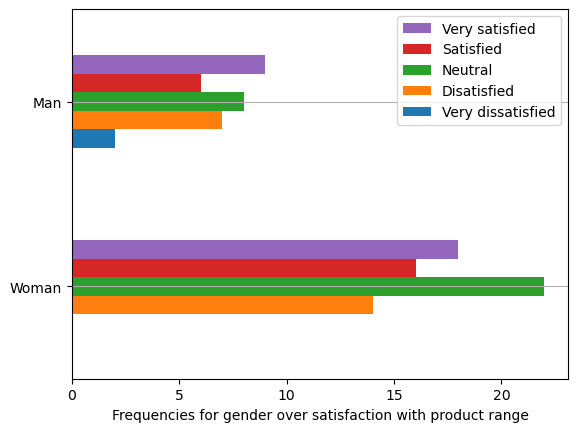

In [7]:
df_freq.plot.barh(legend = 'reverse')

plt.xlabel('Frequencies for gender over satisfaction with product range')

plt.grid(axis = 'y')

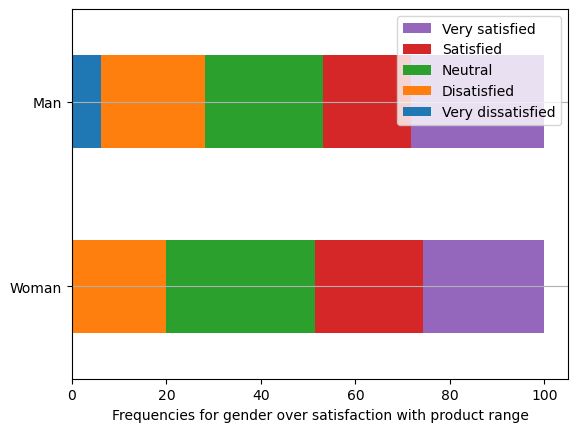

In [8]:
df_percents.plot.barh(legend = 'reverse', stacked = True)

plt.xlabel('Frequencies for gender over satisfaction with product range')

plt.grid(axis = 'y')

# Important note!!
The CHI2 test must be done for the counts/frequency table, not for the percentages table, Hence, the df_percentages is not the table to use with the test below!


In [9]:
# Let's see df_freq ones again
df_freq

,Very dissatisfied,Disatisfied,Neutral,Satisfied,Very satisfied
Woman,0,14,22,16,18
Man,2,7,8,6,9


In [10]:
chi2_contingency(df_freq)

Chi2ContingencyResult(statistic=4.941038961038961, pvalue=0.2934009452510216, dof=4, expected_freq=array([[ 1.37254902, 14.41176471, 20.58823529, 15.09803922, 18.52941176],
       [ 0.62745098,  6.58823529,  9.41176471,  6.90196078,  8.47058824]]))

# The interpretation, part 1
The p-value is ~0.29, This means that the chi2 test's null hypothesis (H0) remains valid. Remember that H0 means that there is no dependency between variables. The other hypothesis is H1:There is dependency between variables. Then how strong dependency there is, is interpreted by the p-values in the following way:

* p<0,05  statistically almost significant dependency/ Tilastollisesti melkein merkitsevä riippuvuus
* p<0,01  statistically significant dependency/ Tilastollisesti merkitsevä riippuvuus
* p<0,001 statistically very significant dependency/ Tilastollisesti erittäin merkitsevä riippuvuus



The interpretation, part 2
In reality, there is actually one more thing to this. And I have been leaving that a bit of extra, although in practice that would always need to be taken into account! But this is a course and we are progressing step-by-step :) 

So what is the thing? Well let's see the df_freq again

In [11]:
df_freq

,Very dissatisfied,Disatisfied,Neutral,Satisfied,Very satisfied
Woman,0,14,22,16,18
Man,2,7,8,6,9


The thing is that, for example, there seem to be 0 very dissatisfied female clients and just 2 such male clients.
The amount of data for those categories in practice is too small to make any conclusions to be generalized to the whole population. Let's remove those categories and try again.

In [12]:
# Combine the classes for sat_product_range
df_freq_combined = df_freq.copy()
df_freq_combined['Disatisfied'] += df_freq_combined['Very dissatisfied']
df_freq_combined['Very satisfied'] += df_freq_combined['Satisfied']
df_freq_combined = df_freq_combined.drop(columns=['Very dissatisfied', 'Satisfied'])

df_freq_combined.columns = ['Disatisfied', 'Neutral', 'Very satisfied']
df_freq_combined

,Disatisfied,Neutral,Very satisfied
Woman,14,22,34
Man,9,8,15


Ok, now you can see that we have more data for each category such that we can be bit more sure that also chi2 test would give us more reliable results. That is exactly the case with the CHI2 - there needs to be "enough" data for these categories. 

What is "enough" then? There seem to be bit of fluctuation on this how this is exactly defined, depending who you ask. But let me explain this a bit

First, let's add one column to the df_freq.

In [13]:
df_freq2 = df_freq.copy()
df_freq2['Sum_col'] = df_freq2.sum(axis=1)
df_freq2.loc['Sum_row'] = df_freq2.sum()  # This line is not needed, but you could have studied the situation also on column direction
df_freq2

,Very dissatisfied,Disatisfied,Neutral,Satisfied,Very satisfied,Sum_col
Woman,0,14,22,16,18,70
Man,2,7,8,6,9,32
Sum_row,2,21,30,22,27,102


So there are 70+32=102 observations. Let's think about the situation as if there would not be any dependency between these variables. Then basically the distribution for women for their "sat" answers should be the same as for men (But of course, in practice there would be some fluctuation.) This would mean that the distribution for "sat" values for women should be be identical with the distribution of values on Sum_row column. And also the distribution for "sat" values for men should be be identical with the distribution of values on Sum_row column

So these are the frequencies that we would ** expect ** given that there are 70 answers from women and 32 answers from men.

In [14]:
expected_frequencies = df_freq2.copy()

for col in df_freq2.columns[:-1]:  # Exclude the 'Sum_col' column
    for row in df_freq2.index[:-1]:  # Exclude the 'Sum_row' row
        expected_frequencies.loc[row, col] = (df_freq2.loc[row, 'Sum_col'] * df_freq2.loc['Sum_row', col]) / df_freq2.loc['Sum_row', 'Sum_col']

expected_frequencies
# do not worry about the warnings

C:\Users\tlahti\AppData\Local\Temp\ipykernel_31544\352451219.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '1.3725490196078431' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  expected_frequencies.loc[row, col] = (df_freq2.loc[row, 'Sum_col'] * df_freq2.loc['Sum_row', col]) / df_freq2.loc['Sum_row', 'Sum_col']
C:\Users\tlahti\AppData\Local\Temp\ipykernel_31544\352451219.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '14.411764705882353' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  expected_frequencies.loc[row, col] = (df_freq2.loc[row, 'Sum_col'] * df_freq2.loc['Sum_row', col]) / df_freq2.loc['Sum_row', 'Sum_col']
C:\Users\tlahti\AppData\Local\Temp\ipykernel_31544\352451219.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and wi

,Very dissatisfied,Disatisfied,Neutral,Satisfied,Very satisfied,Sum_col
Woman,1.372549,14.411765,20.588235,15.098039,18.529412,70
Man,0.627451,6.588235,9.411765,6.901961,8.470588,32
Sum_row,2.000000,21.000000,30.000000,22.000000,27.000000,102


Let's see how different this is from the observed frequencies

In [15]:
df_freq2

,Very dissatisfied,Disatisfied,Neutral,Satisfied,Very satisfied,Sum_col
Woman,0,14,22,16,18,70
Man,2,7,8,6,9,32
Sum_row,2,21,30,22,27,102


Not too much difference on my opinion. So, I might say that "IT SEEMS like there would not be any depency between the variables. But on the other hand we have run the chi2 test already and that game us the p-value 0.29 so we were already doing better than just saying that it SEEMS.

Let's not cover more than that what comes to the mathematical part of the Chi2 test that those expected frequencies. Those are the ones that the test will be using "under the hood". 

The take away here is that in practice you should always check if for expected(!) frequencies there are some classes with 0 observations. So at least 1. As you can see above, there are 0 observations for women who would have been very dissatisfied with the product_range. So we should not use the test for testing that crosstabulated table with chi2! The results might not be reliable!

Instead, you should do as we did, combine some "sat" categories and get more observation for cells and then run the chi2 test.

The other thing that people are often mentioning is that you should not have such cell that have <=5 observations more that 20% of all cells.

There are also some other conciderations that people report but let's now stop and let me say that it is ok for this course to run chi2 test with relaxed conditions such that you do not need to calculate the expected frequencies but you just decide based on the observed frequencies whether there is enough data to be used with Chi2 test. This is because you probably have lot to learn anyway, and I trust that you remember that in practice there is conditions for use of chi2. Ok?

But everything has its limits! See still the example below, for that kind of data you should surely not apply the chi2 test. That is why we have learned to make the categorization for the numerical variables first!

In [ ]:
df_freq3 = pd.crosstab(df_orig['gender'], df_orig['age'])
df_freq3.index = ['Woman', 'Man']
df_freq3.T  # T is used to transpose the table to make it more readable

,Woman,Man
age,,
19,0,1
20,1,1
21,0,1
22,2,0
24,2,0
25,2,0
26,3,0
27,3,0
28,1,2
